Multimodal Signal Analysis with pyPSG
=======================================

This tutorial provides a detailed walkthrough of multimodal physiological signal analysis using **pyPSG**,
focusing on how different signals (ECG, PPG, HRV, and SpO2) are processed and how biomarkers are derived from them.

Our objectives are to:

- loading and selecting signals from an EDF file
- preprocessing signals
- detecting fiducial points
- extracting biomarkers

This tutorial assumes that you have already completed the setup of **pyPSG**.
For installation and initial configuration, see the [example code tutorial](https://pypsg-github.readthedocs.io/en/latest/tutorials/example.html) .

Download data
-------------

For this tutorial, download the sample dataset from the following repository:

[Sample data (GitHub)](https://github.com/pszabolcsm/pyPSG/tree/main/sample_data)

Loading EDF data
----------------

First, select the EDF file containing the physiological signals:

In [1]:
from pyPSG.utils import select_file

edf_path = select_file(
    title="Select EDF file",
    filetypes=[("EDF files", "*.edf")]
)

Next, define the channel names corresponding to the signals in the dataset:

In [2]:
channels = {
        "ppg": "Pleth",
        "ecg": "EKG",
        "spo2": "SpO2"
    }

Load the selected signals from the EDF file:

In [3]:
from pyPSG.IO.edf_read import read_edf_signals

signals = read_edf_signals(edf_path, channels.values())

The signals are stored in a dictionary-like structure, where each entry contains:

```python
signals["Pleth"]["signal"]   # raw signal values
signals["Pleth"]["fs"]       # sampling frequency


This structure is used throughout the analysis pipeline.

After loading the data, plot the raw signals:

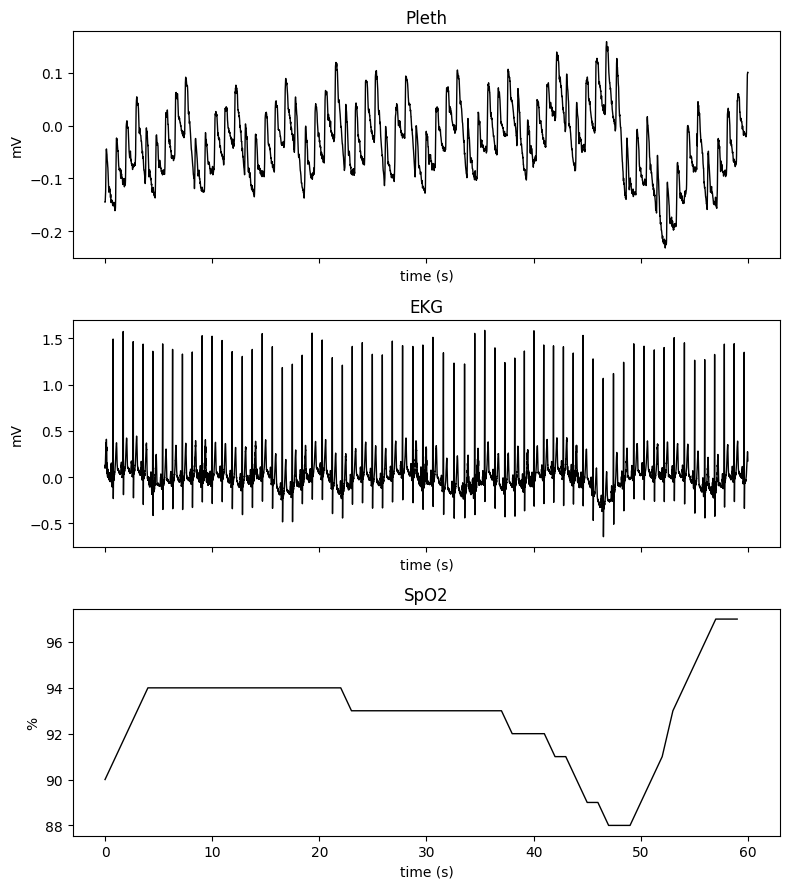

In [4]:
from pyPSG.IO.plot import plot_raw_data

plot_raw_data(signals)

SpO2 signal processing
----------------------

If a SpO2 channel is available, the signal is processed to extract oxygen saturation biomarkers.

First, retrieve the SpO2 signal and its sampling frequency:

In [5]:
spo2_signal = signals[channels["spo2"]]["signal"]
spo2_fs = signals[channels["spo2"]]["fs"]

Remove physiologically implausible values (below 50% or above 100%):

In [6]:
from pobm.prep import set_range

spo2_signal = set_range(spo2_signal)

Apply a median filter to smooth the signal:

In [7]:
from pobm.prep import median_spo2

spo2_signal = median_spo2(spo2_signal, FilterLength=301)

Create a corresponding time axis:

In [8]:
import numpy as np

time_signal = np.arange(0, len(spo2_signal)) / spo2_fs

Finally, compute SpO2 biomarkers:

In [9]:
from pyPSG.biomarkers.get_spo2_bm import extract_biomarkers_per_signal

spo2_bm = extract_biomarkers_per_signal(
    signal=spo2_signal,
    patient="Patient 1",
    time_begin=time_signal[0],
    time_end=time_signal[-1]
)

The resulting biomarkers are stored for later use.

PPG signal processing
---------------------

If a PPG channel is available, the signal is processed to extract morphological
features and derive physiological biomarkers.

### Prepare the signal

Wrap the raw signal and its metadata into a structured object:

In [10]:
from dotmap import DotMap

ppg_signal = DotMap()
ppg_signal.v = signals[channels["ppg"]]["signal"]
ppg_signal.fs = signals[channels["ppg"]]["fs"]
ppg_signal.start_sig = 0
ppg_signal.end_sig = len(ppg_signal.v)
ppg_signal.name = "custom_ppg"

### Preprocessing

Apply bandpass filtering and smoothing to obtain different signal representations:

In [11]:
import pyPPG.preproc as PP

filtering = True
fL = 0.5
fH = 12
order = 4
sm_wins = {"ppg": 50, "vpg": 10, "apg": 10, "jpg": 10}

prep = PP.Preprocess(fL=fL, fH=fH, order=order, sm_wins=sm_wins)

ppg_signal.filtering = filtering
ppg_signal.fL = fL
ppg_signal.fH = fH
ppg_signal.order = order
ppg_signal.sm_wins = sm_wins

ppg_signal.ppg, ppg_signal.vpg, ppg_signal.apg, ppg_signal.jpg = prep.get_signals(s=ppg_signal)

This step generates the filtered PPG signal and its derivatives (VPG, APG, JPG),
which are required for feature extraction.

### Fiducial point detection

Detect characteristic points in the PPG waveform:

In [12]:
import pyPPG.fiducials as FP
from pyPPG import PPG, Fiducials

s = PPG(s=ppg_signal, check_ppg_len=True)

fpex = FP.FpCollection(s=s)
ppg_fiducials = fpex.get_fiducials(s=s)

fp = Fiducials(fp=ppg_fiducials)

Fiducial points represent key landmarks in the waveform (e.g., systolic peak,
dicrotic notch), which are essential for further analysis.

Visualize the detected fiducial points on the PPG waveform:

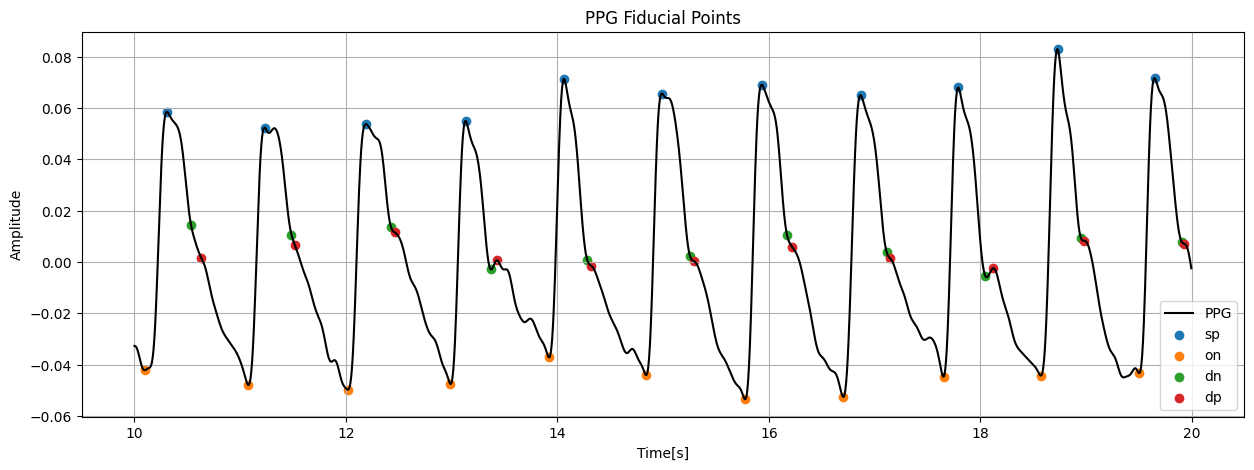

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fid_df = fp.get_fp()

start = int(10 * s.fs)
end = int(20 * s.fs)

ppg_sig = s.ppg[start:end]
x = np.arange(start, end) / s.fs

plt.figure(figsize=(15,5))
plt.plot(x, ppg_sig, color="black", label="PPG")

for col in ["sp", "on", "dn", "dp"]:
    idx = fid_df[col].dropna().astype(int)
    idx = idx[(idx >= start) & (idx < end)]

    plt.scatter(idx/s.fs, s.ppg[idx], label=col)

plt.title("PPG Fiducial Points")
plt.xlabel("Time[s]")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.show()


### Biomarker extraction

Compute morphological biomarkers from the PPG signal:

In [14]:
import pyPPG.biomarkers as BM
from pyPPG import Biomarkers

bmex = BM.BmCollection(s=s, fp=fp)
bm_defs, bm_vals, bm_stats = bmex.get_biomarkers()

ppg_bm = Biomarkers(
    bm_defs=bm_defs,
    bm_vals=bm_vals,
    bm_stats=bm_stats
    )

no more peaks
no more peaks
no more peaks
no more peaks


ECG signal processing
---------------------

If an ECG channel is available, the signal is processed to detect cardiac events
and extract clinically relevant biomarkers.

### Preprocessing

Apply filtering to remove powerline interference and noise:

In [15]:
from pecg import Preprocessing as Pre
from pyPSG.utils import HiddenPrints

pre = Pre.Preprocessing(
    signals[channels["ecg"]]["signal"],
    signals[channels["ecg"]]["fs"]
)

# Remove powerline noise (50 Hz in Europe, 60 Hz in the US)
with HiddenPrints(): # to avoid long verbose
    filtered_signal = pre.notch(n_freq=50)

# Apply bandpass filtering to remove baseline wander and high-frequency noise
filtered_signal = Pre.Preprocessing(
    filtered_signal,
    signals[channels["ecg"]]["fs"]
).bpfilt()

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


### Fiducial point detection

Detect R-peaks and compute fiducial points:

In [16]:
from pecg.ecg import FiducialPoints as Fp

fp = Fp.FiducialPoints(
    filtered_signal,
    signals[channels["ecg"]]["fs"]
)

# Detect peaks using the jqrs algorithm
jqrs_peaks = fp.jqrs()

# Compute fiducial points using the Wavedet algorithm (MATLAB Runtime required)
matlab_path = "C:\\Program Files\\MATLAB\\MATLAB Runtime\\v910" # Replace this path with your local MATLAB Runtime installation path
ecg_fiducials = fp.wavedet(matlab_path, peaks=jqrs_peaks)

Visualize the detected ECG fiducial points on the filtered ECG signal:

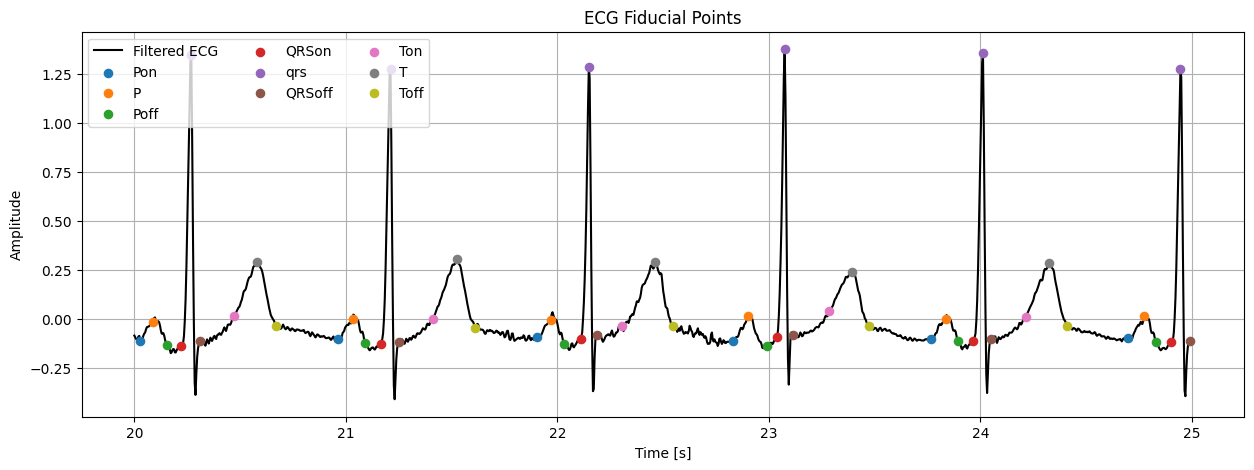

In [17]:
import matplotlib.pyplot as plt
import numpy as np

ecg_fs = signals[channels["ecg"]]["fs"]

start = int(20 * ecg_fs)
end = int(25 * ecg_fs)

ecg_sig = filtered_signal[start:end]
time = np.arange(start, end) / ecg_fs

fid = ecg_fiducials[0]

plt.figure(figsize=(15, 5))
plt.plot(time, ecg_sig, color="black", label="Filtered ECG")

ecg_fiducial_labels = [
    "Pon",
    "P",
    "Poff",
    "QRSon",
    "qrs",
    "QRSoff",
    "Ton",
    "T",
    "Toff"
]

for label in ecg_fiducial_labels:

    idx = fid[label]

    idx = idx[(idx >= start) & (idx < end)].astype(int)

    plt.scatter(idx / ecg_fs, filtered_signal[idx], zorder=5, s=35, label=label)

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("ECG Fiducial Points")
plt.legend(ncol=3)
plt.grid(True)

plt.show()

### Biomarker extraction

Compute interval- and waveform-based biomarkers:

In [18]:
from pecg.ecg import Biomarkers as Bm

bm = Bm.Biomarkers(
    filtered_signal,
    signals[channels["ecg"]]["fs"],
    ecg_fiducials
)

ints, stat_i = bm.intervals()
waves, stat_w = bm.waves()

ecg_bm = {
    "ints": ints,
    "stat_i": stat_i,
    "waves": waves,
    "stat_w": stat_w,
}

Heart rate variability (HRV) analysis
-------------------------------------

Heart rate variability (HRV) quantifies fluctuations in the time intervals
between successive cardiac cycles.

In this analysis, HRV is derived from both ECG and PPG signals using peak-to-peak intervals.

### ECG-based HRV

HRV computed from ECG signals is based on the intervals between successive heartbeats:


In [19]:
rr_intervals = np.diff(jqrs_peaks) / signals[channels["ecg"]]["fs"]

Compute HRV metrics:

In [20]:
from pyPSG.biomarkers import hrv_bms as hrv

hrv_bm = hrv.get_all_metrics(rr_intervals, 30)

### PPG-based HRV

HRV can also be approximated from the PPG signal by analyzing the intervals
between successive pulse peaks:

In [21]:
ppg_peaks = ppg_fiducials.sp

Compute the intervals between consecutive peaks:

In [22]:
rr_intervals = np.diff(ppg_peaks) / signals[channels["ppg"]]["fs"]


Compute HRV metrics:

In [23]:
ppg_hrv_bm = hrv.get_all_metrics(rr_intervals, 30)